In [57]:
import pandas as pd
import time
import requests
import yfinance as yf
import matplotlib.pyplot as plt

In [22]:
filing=pd.read_csv("data/processed/filings_scored.csv", dtype={"accession": str})
filing.head()

,ticker,accession,text,length,vader_compound,lm_score
0,AAPL,000032019317000006,\n EX-99.1\n 2\n a8-kexhibit991q32017712017.ht...,1933,0.9800,0.017544
1,AAPL,000032019317000067,\n EX-99.1\n 2\n a8-kexhibit991q420179302017.h...,2125,0.9938,0.018692
2,AAPL,000032019318000005,\n EX-99.1\n 2\n a8-kexhibit991q12018123020.ht...,2153,0.9899,0.024615
3,AAPL,000032019318000067,\n EX-99.1\n 2\n a8-kexhibit991q220183312018.h...,2801,0.9953,0.009501
4,AAPL,000032019318000098,\n EX-99.1\n 2\n a8-kexhibit991q320186302018.h...,1867,0.9778,0.014545


In [23]:
companies = pd.read_csv("companies.csv", dtype={"cik": str})
my_dict = {"User-Agent": "Prudhvi Raj your_email@example.com"}
print(companies[["ticker", "cik"]])

  ticker         cik
0   NVDA  0001045810
1   AAPL  0000320193
2  GOOGL  0001652044
3   MSFT  0000789019
4   AMZN  0001018724
5   TSLA  0001318605
6   COST  0000909832
7    UNH  0000731766
8      T  0000732717
9     CF  0001324404


In [24]:
date_records = []
for cik, ticker in zip(companies["cik"],companies["ticker"]):
    URL=f"https://data.sec.gov/submissions/CIK{cik}.json"
    r=requests.get(URL,headers=my_dict)
    time.sleep(0.2)
    if r.status_code!=200:
        print(f"Failed {ticker}: {r.status_code}")
        continue
    recent = r.json()["filings"]["recent"]
    for acc, date in zip(recent["accessionNumber"], recent["filingDate"]):
        date_records.append({
            "accession": acc.replace("-", ""),
            "filing_date": date
        })
dates = pd.DataFrame(date_records)
print(dates.shape)
dates.head()

(10017, 2)


,accession,filing_date
0,000215218826000007,2026-10-13
1,000119764726000011,2026-10-09
2,000169684126000014,2026-09-23
3,000119903926000016,2026-09-22
4,000192109426001040,2026-09-21


In [25]:
filing

,ticker,accession,text,length,vader_compound,lm_score
0,AAPL,000032019317000006,\n EX-99.1\n 2\n a8-kexhibit991q32017712017.ht...,1933,0.9800,0.017544
1,AAPL,000032019317000067,\n EX-99.1\n 2\n a8-kexhibit991q420179302017.h...,2125,0.9938,0.018692
2,AAPL,000032019318000005,\n EX-99.1\n 2\n a8-kexhibit991q12018123020.ht...,2153,0.9899,0.024615
3,AAPL,000032019318000067,\n EX-99.1\n 2\n a8-kexhibit991q220183312018.h...,2801,0.9953,0.009501
4,AAPL,000032019318000098,\n EX-99.1\n 2\n a8-kexhibit991q320186302018.h...,1867,0.9778,0.014545
...,...,...,...,...,...,...
187,UNH,000073176623000026,\n EX-99.1\n 2\n a2023q1exhibit991.htm\n EX-99...,7272,0.9996,0.020448
188,UNH,000073176623000049,\n EX-99.1\n 2\n a2023q2exhibit991.htm\n EX-99...,7359,0.9997,0.021093
189,UNH,000073176623000058,\n EX-99.1\n 2\n a2023q3exhibit991.htm\n EX-99...,7655,0.9996,0.017431
190,UNH,000073176624000023,\n EX-99.1\n 2\n a2023q4exhibit991.htm\n EX-99...,7473,0.9996,0.018234


In [26]:
filing = filing.merge(dates, on="accession", how="left")
print(filing.shape)
print(filing["filing_date"].isna().sum())

(192, 7)
0


In [27]:
filing[["ticker", "accession", "filing_date", "vader_compound", "lm_score"]].head()

,ticker,accession,filing_date,vader_compound,lm_score
0,AAPL,000032019317000006,2017-08-01,0.9800,0.017544
1,AAPL,000032019317000067,2017-11-02,0.9938,0.018692
2,AAPL,000032019318000005,2018-02-01,0.9899,0.024615
3,AAPL,000032019318000067,2018-05-01,0.9953,0.009501
4,AAPL,000032019318000098,2018-07-31,0.9778,0.014545


In [28]:
filing["filing_date"] = pd.to_datetime(filing["filing_date"])
print(filing["filing_date"].dtype)

datetime64[us]


In [29]:
filing.to_csv("data/processed/filings_dated.csv", index=False)

In [30]:
test = yf.download("AAPL", start="2015-01-01", end="2026-10-20")
print(test.shape)
test.head()

[*********************100%***********************]  1 of 1 completed

(2966, 5)


Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2015-01-02,24.171759,24.638258,23.734000,24.627203,212818400
2015-01-05,23.490801,24.021417,23.305086,23.941824,257142000
2015-01-06,23.493017,23.751692,23.132640,23.554922,263188400
2015-01-07,23.822426,23.921916,23.590281,23.700826,160423600
2015-01-08,24.737745,24.795229,24.032468,24.149647,237458000


In [31]:
tickers = list(companies["ticker"])
prices = yf.download(tickers, start="2015-01-01", end="2026-10-20")["Close"]
print(prices.shape)
prices.tail()

[*********************100%***********************]  10 of 10 completed

(2966, 10)


Ticker,AAPL,AMZN,CF,COST,GOOGL,MSFT,NVDA,T,TSLA,UNH
Date,,,,,,,,,,
2026-10-13,341.269989,258.579987,117.250000,954.630005,353.779999,543.450012,228.520004,22.850000,375.230011,377.760010
2026-10-14,342.959991,254.080002,119.459999,982.000000,347.640015,533.690002,221.300003,23.049999,367.160004,395.619995
2026-10-15,342.000000,254.759995,119.769997,978.010010,349.220001,539.440002,217.229996,23.500000,362.440002,406.670013
2026-10-16,343.459991,250.000000,120.849998,989.109985,340.589996,529.049988,214.130005,23.440001,354.720001,401.429993
2026-10-19,342.940002,262.450012,118.510002,995.530029,344.179993,533.520020,217.089996,23.200001,368.059998,406.880005


In [32]:
prices.to_csv("data/processed/prices.csv")

In [33]:
def forward_returns(ticker, filing_date, prices, horizons=(1, 5, 20)):
    series = prices[ticker].dropna()
    pos = series.index.searchsorted(filing_date)
    if pos >= len(series):
        return {f"ret_{h}d": None for h in horizons}

    base_price = series.iloc[pos]

    results = {}
    for h in horizons:
        future_pos = pos + h
        if future_pos < len(series):
            future_price = series.iloc[future_pos]
            results[f"ret_{h}d"] = (future_price - base_price) / base_price
        else:
            results[f"ret_{h}d"] = None
    return results

In [34]:
test_date = pd.to_datetime("2017-08-01")
print(forward_returns("AAPL", test_date, prices))

{'ret_1d': np.float64(0.0472508129390282), 'ret_5d': np.float64(0.06684415150003016), 'ret_20d': np.float64(0.08996814046709037)}


In [50]:
returns_data = filing.apply(
    lambda row: forward_returns(row["ticker"], row["filing_date"], prices),
    axis=1
)
returns_df=pd.DataFrame(list(return_data))
filing = pd.concat([filing.reset_index(drop=True), returns_df], axis=1)

In [51]:
returns_df

,ret_1d,ret_5d,ret_20d
0,0.047251,0.066844,0.089968
1,0.026114,0.046220,0.021146
2,-0.043390,-0.075277,0.054527
3,0.044175,0.100236,0.113087
4,0.058910,0.088392,0.158603
...,...,...,...
187,-0.012583,-0.054651,-0.040173
188,0.008143,0.054897,0.057980
189,-0.002540,-0.022933,0.003356
190,-0.004525,-0.016337,-0.007421


In [52]:
print(filing.shape)
filing[["ticker", "filing_date", "vader_compound", "lm_score", "ret_1d", "ret_5d", "ret_20d"]].head()

(192, 13)


,ticker,filing_date,vader_compound,lm_score,ret_1d,ret_5d,ret_20d
0,AAPL,2017-08-01,0.9800,0.017544,0.047251,0.066844,0.089968
1,AAPL,2017-11-02,0.9938,0.018692,0.026114,0.046220,0.021146
2,AAPL,2018-02-01,0.9899,0.024615,-0.043390,-0.075277,0.054527
3,AAPL,2018-05-01,0.9953,0.009501,0.044175,0.100236,0.113087
4,AAPL,2018-07-31,0.9778,0.014545,0.058910,0.088392,0.158603


In [53]:
print(filing[["ret_1d", "ret_5d", "ret_20d"]].isna().sum())

ret_1d     0
ret_5d     0
ret_20d    2
dtype: int64


In [54]:
filing.to_csv("data/processed/filings_returns.csv", index=False)

In [55]:
cols = ["vader_compound", "lm_score", "ret_1d", "ret_5d", "ret_20d"]
filing[cols].corr()

,vader_compound,lm_score,ret_1d,ret_5d,ret_20d
vader_compound,1.000000,0.457717,-0.077931,-0.168758,-0.064957
lm_score,0.457717,1.000000,-0.107690,-0.095892,-0.039746
ret_1d,-0.077931,-0.107690,1.000000,0.725160,0.415049
ret_5d,-0.168758,-0.095892,0.725160,1.000000,0.575540
ret_20d,-0.064957,-0.039746,0.415049,0.575540,1.000000


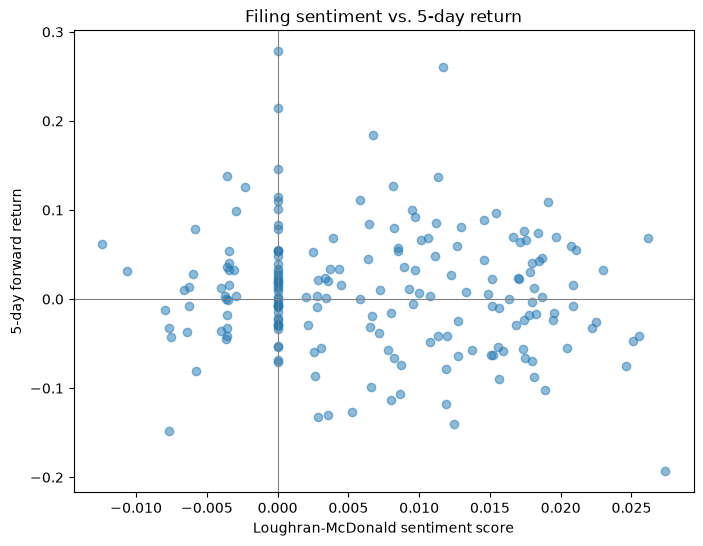

In [56]:


x = filing["lm_score"]
y = filing["ret_5d"]

plt.figure(figsize=(8, 6))
plt.scatter(x, y, alpha=0.5)
plt.xlabel("Loughran-McDonald sentiment score")
plt.ylabel("5-day forward return")
plt.title("Filing sentiment vs. 5-day return")
plt.axhline(0, color="gray", linewidth=0.8)
plt.axvline(0, color="gray", linewidth=0.8)
plt.show()